# Titanic — Baselines

**Goal:** set the bar every later model must beat, and build a leak-free evaluation setup.

1. Two reference rules that learn almost nothing: *everyone died* and *women survived*.
2. A logistic regression on the features chosen in `01_eda.ipynb`.
3. Error analysis: where does the model go wrong?
4. A first submission file.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path("../src").resolve()))
from titanic.data import load_raw
from titanic.features import make_preprocessor

SEED = 42
DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
REPORT_DIR = Path("../reports")
SUBMISSION_DIR = Path("../submissions")

sns.set_theme(style="whitegrid", palette="deep")


def save_fig(fig, name):
    """Save a figure to reports/figures for the README and the blog post."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


train = load_raw(DATA_DIR / "train.csv")
test = load_raw(DATA_DIR / "test.csv")
X = train.drop(columns="Survived")
y = train["Survived"]
print(f"X: {X.shape}, y: {y.shape}, test: {test.shape}")

X: (891, 11), y: (891,), test: (418, 11)


## 1. Evaluation setup

**Cross-validation (CV):** the 891 training rows are split into 5 parts (*folds*). The model is trained on 4 parts
and scored on the 5th, five times, so every row is used for scoring exactly once. The mean of the 5 scores is a
more reliable estimate than a single train/validation split, and the standard deviation shows how much the score
depends on which rows happened to land in the validation part.

**Stratified** means every fold keeps the same share of survivors (~38%). `shuffle=True` with a fixed `random_state`
makes the folds random but reproducible, and every model below is scored on **the same 5 folds**.

**No leakage:** all preprocessing that learns from data (median age per title, scaling, one-hot categories) is part
of the model `Pipeline`. In each CV round it is fitted on the 4 training folds only and never sees the validation fold.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}


def evaluate(name, model):
    """Score `model` with 5-fold CV on the shared folds and store the fold scores."""
    scores = cross_validate(model, X, y, cv=cv, scoring="accuracy", return_train_score=True)
    results[name] = scores
    print(f"{name:<22} CV accuracy {scores['test_score'].mean():.3f} ± {scores['test_score'].std():.3f}"
          f"   (train {scores['train_score'].mean():.3f})")
    return scores

## 2. Reference rules

In [3]:
class GenderRule(BaseEstimator, ClassifierMixin):
    """Predict that every woman survived and every man died (Kaggle's sample submission)."""

    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        return (X["Gender"] == "female").astype(int).to_numpy()


evaluate("Majority class", DummyClassifier(strategy="most_frequent"))
evaluate("Gender rule", GenderRule());

Majority class         CV accuracy 0.616 ± 0.002   (train 0.616)
Gender rule            CV accuracy 0.787 ± 0.019   (train 0.787)


The gender rule uses a single column and no learning at all, yet it is far above the majority class.
This is the real bar: a model is only interesting if it beats ~79%.

## 3. Logistic regression

Logistic regression computes a weighted sum of the features and squeezes it through the sigmoid function into a
probability between 0 and 1; above 0.5 it predicts *survived*. The weights are learned from the training folds.
It is fast, hard to overfit on 20 features, and its weights are easy to read, which makes it a good first model.

In [4]:
logreg = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000)),
])
logreg

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('engineer', ...), ('impute_age', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...001FDD69FDEE0>
,"inverse_fu

In [5]:
evaluate("Logistic regression", logreg);

Logistic regression    CV accuracy 0.831 ± 0.010   (train 0.834)


## 4. Comparison

In [6]:
summary = pd.DataFrame({
    name: {
        "cv_mean": s["test_score"].mean(),
        "cv_std": s["test_score"].std(),
        "train_mean": s["train_score"].mean(),
    }
    for name, s in results.items()
}).T
summary["train_cv_gap"] = summary["train_mean"] - summary["cv_mean"]
summary = summary.round(4)
summary.to_csv(REPORT_DIR / "cv_results.csv", index_label="model")
summary

,cv_mean,cv_std,train_mean,train_cv_gap
Majority class,0.6162,0.0023,0.6162,-0.0000
Gender rule,0.7868,0.0188,0.7868,0.0000
Logistic regression,0.8305,0.0099,0.8339,0.0034


In [7]:
fold_scores = pd.DataFrame({name: s["test_score"] for name, s in results.items()})
fold_scores.index = [f"fold {i + 1}" for i in range(len(fold_scores))]
fold_scores["logreg - gender"] = fold_scores["Logistic regression"] - fold_scores["Gender rule"]
fold_scores.round(3)

,Majority class,Gender rule,Logistic regression,logreg - gender
fold 1,0.615,0.788,0.844,0.056
fold 2,0.618,0.775,0.826,0.051
fold 3,0.618,0.787,0.815,0.028
fold 4,0.618,0.764,0.837,0.073
fold 5,0.612,0.820,0.831,0.011


Because all models are scored on the same folds, they can be compared **fold by fold**. A model that wins on every
fold is a more convincing improvement than one whose mean is slightly higher but which loses on some folds.

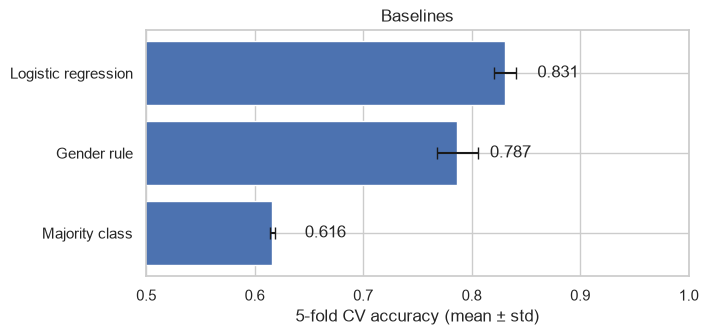

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
order = summary.sort_values("cv_mean").index
ax.barh(order, summary.loc[order, "cv_mean"], xerr=summary.loc[order, "cv_std"], capsize=4)
for i, name in enumerate(order):
    ax.text(summary.loc[name, "cv_mean"] + 0.03, i, f"{summary.loc[name, 'cv_mean']:.3f}", va="center")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("5-fold CV accuracy (mean ± std)")
ax.set_title("Baselines")
save_fig(fig, "baseline_comparison")
plt.show()

**Train vs CV:** the train score is measured on rows the model has seen, the CV score on rows it has not.
A large gap means the model memorises the training data (*overfitting*). A gap of a point or two is normal.

## 5. Error analysis

`cross_val_predict` returns, for every training row, the prediction made by the model that did **not** see that row
(*out-of-fold* predictions). They show where the model fails without being optimistic.

Out-of-fold accuracy: 0.831

              precision    recall  f1-score   support

        died      0.853     0.876     0.864       549
    survived      0.792     0.757     0.774       342

    accuracy                          0.831       891
   macro avg      0.822     0.817     0.819       891
weighted avg      0.830     0.831     0.830       891



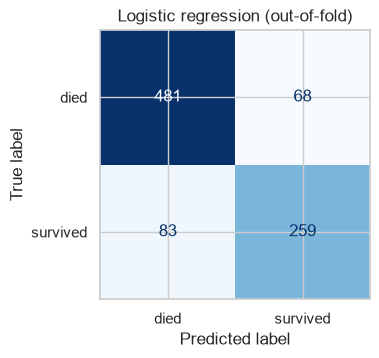

In [9]:
oof_pred = cross_val_predict(logreg, X, y, cv=cv)
print(f"Out-of-fold accuracy: {(oof_pred == y).mean():.3f}\n")
print(classification_report(y, oof_pred, target_names=["died", "survived"], digits=3))

fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(y, oof_pred, display_labels=["died", "survived"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Logistic regression (out-of-fold)")
save_fig(fig, "logreg_confusion_matrix")
plt.show()

- **Precision (survived):** of the passengers the model *says* survived, how many really did.
- **Recall (survived):** of the passengers who *really* survived, how many the model found.
- In the confusion matrix, rows are the truth and columns the prediction: the off-diagonal cells are the mistakes.

In [10]:
errors = train.assign(pred=oof_pred, correct=(oof_pred == y))
errors.pivot_table(index="Gender", columns="Pclass", values="correct", aggfunc="mean").round(3)

Pclass,1,2,3
Gender,,,
female,0.968,0.895,0.653
male,0.631,0.926,0.893


In [11]:
# Predicted vs true survival rate per group: where is the model too optimistic or too pessimistic?
group_rates = errors.groupby(["Gender", "Pclass"])[["Survived", "pred"]].mean().round(3)
group_rates.columns = ["true_rate", "predicted_rate"]
group_rates["count"] = errors.groupby(["Gender", "Pclass"]).size()
group_rates

true_rate  predicted_rate  count
Gender Pclass                                  
female 1           0.968           1.000     94
       2           0.921           0.974     76
       3           0.500           0.806    144
male   1           0.369           0.197    122
       2           0.157           0.083    108
       3           0.135           0.029    347

## 6. What did the model learn?

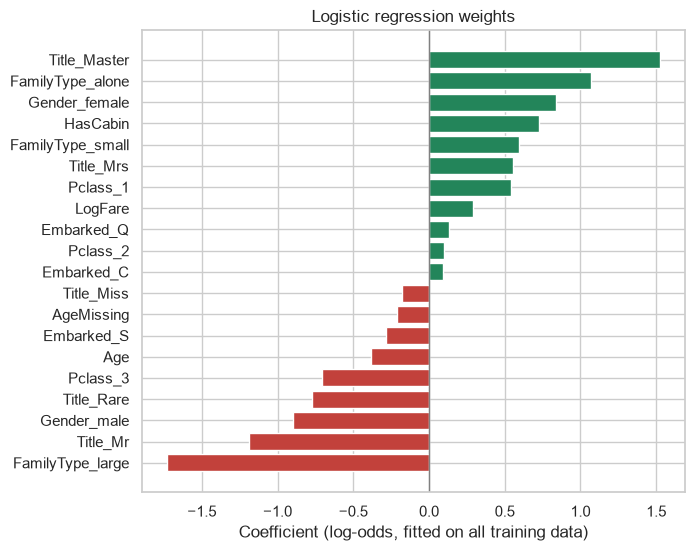

In [12]:
logreg.fit(X, y)
feature_names = logreg.named_steps["prep"].named_steps["columns"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["#c2413b" if c < 0 else "#23855a" for c in coefs]
ax.barh(coefs.index, coefs.values, color=colors)
ax.axvline(0, c="grey", lw=1)
ax.set_xlabel("Coefficient (log-odds, fitted on all training data)")
ax.set_title("Logistic regression weights")
save_fig(fig, "logreg_coefficients")
plt.show()

A positive weight pushes towards *survived*, a negative one towards *died*. `Age` and `LogFare` are standardised,
so their weights mean "per one standard deviation". Weights of correlated features (for example `Gender_male` and
`Title_Mr`, which mark almost the same people) share the effect between them, so read them as a group rather than
one by one.

## 7. First submission file

In [13]:
test_pred = logreg.predict(test)
submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": test_pred})
assert submission.shape == (418, 2) and submission["Survived"].isin([0, 1]).all()

SUBMISSION_DIR.mkdir(exist_ok=True)
submission.to_csv(SUBMISSION_DIR / "02_logreg.csv", index=False)
print(f"Predicted survival rate on test: {submission['Survived'].mean():.3f}")
submission.head()

Predicted survival rate on test: 0.411


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


## 8. Findings

**Scores (5-fold stratified CV, same folds for every model)**

| Model | CV accuracy | Train accuracy |
|---|---|---|
| Majority class ("everyone died") | 0.616 ± 0.002 | 0.616 |
| Gender rule ("women survived") | 0.787 ± 0.019 | 0.787 |
| Logistic regression | **0.831 ± 0.010** | 0.834 |

- Logistic regression beats the gender rule on **all 5 folds** (by 1.1 to 7.3 points), so the gain is not luck
  in one split.
- Train and CV accuracy differ by only 0.3 points: the model does **not overfit**. If anything it is too simple,
  which leaves room for more flexible models.

**Where it fails (out-of-fold predictions)**
- Recall for *survived* is 0.757: about one in four survivors is missed. Precision is 0.792.
- The model essentially learned "women survive, men die", refined by class, title and family:
  - **Women in 3rd class:** really 50% survived, the model predicts 81% → only 65% of them classified correctly.
  - **Men in 1st class:** really 37% survived, the model predicts 20% → only 63% classified correctly.
  - The other four gender x class groups are classified correctly 89–97% of the time.
- These two groups need an **interaction** (the effect of gender depends on class). A logistic regression adds up
  feature effects independently, so it cannot express this unless such a feature is built by hand. Tree models
  learn interactions on their own: this is the motivation for notebook 03.

**What the weights say**
- Strongest pushes towards survival: `Title_Master` (boys), `Gender_female`, `HasCabin`, `Pclass_1`.
  Towards death: `FamilyType_large`, `Title_Mr`, `Gender_male`, `Title_Rare`, `Pclass_3`.
- `FamilyType_alone` gets a *positive* weight although lone travellers survived less often in the EDA (30%).
  The weights are **conditional on all other features**: most lone travellers are adult men, who are already
  penalised through `Title_Mr` and `Gender_male`. Compared to a large family, travelling alone is better.
  One-hot weights should be read relative to the other categories of the same feature.

**Submission**
- `submissions/02_logreg.csv` (418 rows). Predicted survival rate on test: 41.1% (train: 38.4%).

**Next (notebook 03)**
- Random Forest and XGBoost on the same preprocessing and the same folds, compared against 0.831.